In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [3]:
import sys

print("Python version:", sys.version)

Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]


In [4]:
!nvidia-smi

Mon Oct  5 15:04:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [5]:
!pip install -q onnx onnxruntime scikit-learn matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 97.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 81.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 29.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 7.36.2 which is incompatible.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 7.36.2 which is incompatible.


In [6]:
import torch
import torchvision
import onnx
import onnxruntime
import sklearn
import matplotlib
import PIL

print("Torch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("ONNX:", onnx.__version__)
print("ONNX Runtime:", onnxruntime.__version__)
print("Scikit-learn:", sklearn.__version__)

Torch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
ONNX: 1.23.1
ONNX Runtime: 1.30.0
Scikit-learn: 1.6.1


In [7]:
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [8]:
import os

print(os.listdir('/content/drive/MyDrive'))

["I am sharing 'Certificate_64683812.pdf' with you from WPS Office", 'Share Certificate_64683812 (1).pdf', 'Share Certificate_64683959 (1).pdf', 'ConfirmationPage-220411606306.pdf', 'Share Certificate_64683959.pdf', 'Share Certificate_64683812.pdf', 'Share Certificate_64759911.pdf', 'Share Certificate_64721364.pdf', '1656690361812_ConfirmationPage-220320127315.pdf', 'Classroom', 'AdmitCard-220520572537.pdf', 'DOC-20230507-WA0000..pdf', 'markprint.pdf', 'printreceipt_pdf.pdf', '3115864.pdf', 'Alu Fathima eco project M2.pdf', 'FINAL FATHIMA 2121_pagenumber.pdf', '15.COMPUTER SCIENCE AND ENGINEERING.pdf', 'basic_civil_&_mechanical.pdf', '2305206381001698134891.pdf', 'Z2bcc5v.pdf', 'ICSET24SOU(158) (1).pdf', 'ICSET24WSOU(158) (1).pdf', 'ICSET24SOU(158).pdf', 'ICSET24WSOU(158).pdf', 'Fazil P Raphi.png', 'Fazil P Raphi (3).pdf', 'schema', 'oooo', 'Fazil P Raphi (2).pdf', 'Fazil P Raphi.pdf', 'Fazil P Raphi-1.pdf', 'Share Fazil P Raphi-1.pdf', 'Screenshot_2025-06-20-19-37-59-801_com.whatsapp.

In [12]:
import os

DATASET_DIR = "/content/drive/MyDrive/synapse/synpase/archive"

TRAIN_DIR = os.path.join(DATASET_DIR, "Training")
TEST_DIR = os.path.join(DATASET_DIR, "Testing")

print("Training exists:", os.path.exists(TRAIN_DIR))
print("Testing exists:", os.path.exists(TEST_DIR))

Training exists: True
Testing exists: True


In [13]:
print("Training classes:")
print(os.listdir(TRAIN_DIR))

print("\nTesting classes:")
print(os.listdir(TEST_DIR))

Training classes:
['notumor', 'pituitary', 'glioma', 'meningioma']

Testing classes:
['pituitary', 'notumor', 'meningioma', 'glioma']


In [14]:
from pathlib import Path

for folder_name, folder_path in [("Training", TRAIN_DIR), ("Testing", TEST_DIR)]:
    print(f"\n{folder_name}")

    total = 0

    for class_dir in sorted(Path(folder_path).iterdir()):
        if class_dir.is_dir():
            count = len(list(class_dir.glob("*")))
            total += count
            print(f"{class_dir.name}: {count}")

    print(f"Total: {total}")


Training
glioma: 1400
meningioma: 1400
notumor: 1400
pituitary: 1413
Total: 5613

Testing
glioma: 400
meningioma: 400
notumor: 400
pituitary: 400
Total: 1600


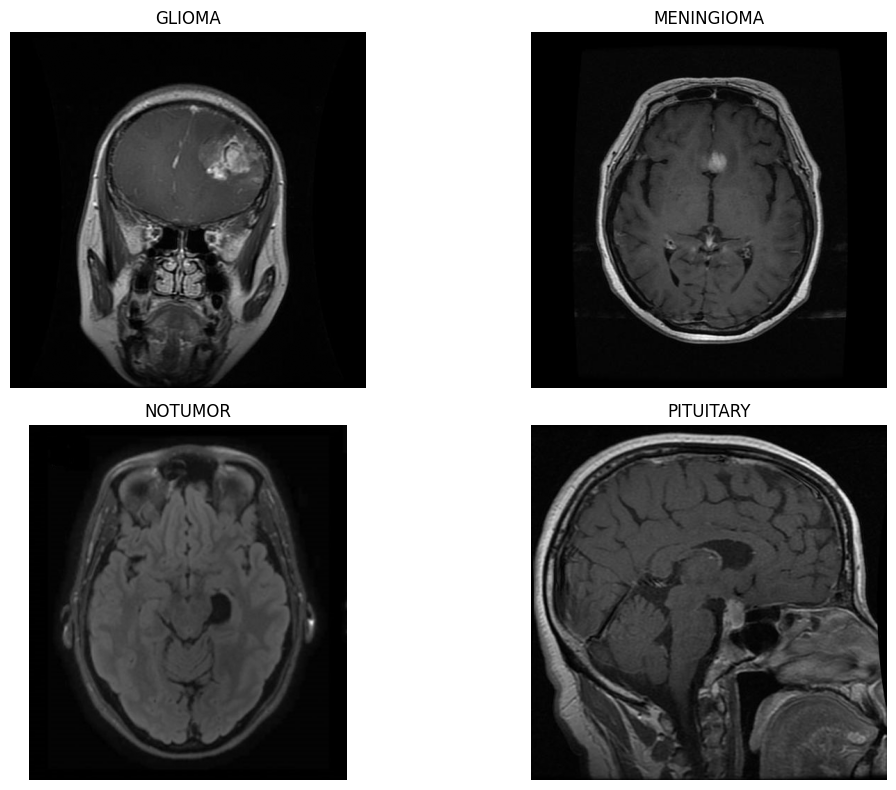

In [15]:
import matplotlib.pyplot as plt
from PIL import Image
import random
import os

classes = ["glioma", "meningioma", "notumor", "pituitary"]

plt.figure(figsize=(12, 8))

for i, class_name in enumerate(classes):
    class_path = os.path.join(TRAIN_DIR, class_name)

    image_files = os.listdir(class_path)
    image_file = random.choice(image_files)

    image_path = os.path.join(class_path, image_file)
    image = Image.open(image_path)

    plt.subplot(2, 2, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(class_name.upper())
    plt.axis("off")

plt.tight_layout()
plt.show()

In [16]:
from torchvision import datasets

train_dataset = datasets.ImageFolder(TRAIN_DIR)
test_dataset = datasets.ImageFolder(TEST_DIR)

print("Classes:", train_dataset.classes)
print("Class mapping:", train_dataset.class_to_idx)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Class mapping: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Training images: 5613
Testing images: 1600


In [17]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [18]:
train_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=test_transform
)

In [19]:
print("Training:", len(train_dataset))
print("Testing:", len(test_dataset))
print("Classes:", train_dataset.classes)

Training: 5613
Testing: 1600
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [20]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [21]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels[:10])

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Labels: tensor([0, 3, 1, 2, 3, 2, 2, 2, 0, 1])


In [22]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

images = images.to(device)
labels = labels.to(device)

print("Device:", device)
print("Images:", images.device)
print("Labels:", labels.device)

Device: cuda
Images: cuda:0
Labels: cuda:0


In [23]:
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

print(model)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 91.8MB/s]

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [24]:
import torch.nn as nn

num_classes = 4

model.fc = nn.Linear(
    model.fc.in_features,
    num_classes
)

model = model.to(device)

In [25]:
print(model.fc)

Linear(in_features=512, out_features=4, bias=True)


In [26]:
criterion = nn.CrossEntropyLoss()

In [27]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

In [28]:
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=10
)

In [29]:
print("Device:", device)
print("Number of classes:", num_classes)
print("Classifier:", model.fc)
print("Initial learning rate:", optimizer.param_groups[0]["lr"])

Device: cuda
Number of classes: 4
Classifier: Linear(in_features=512, out_features=4, bias=True)
Initial learning rate: 0.0001


In [30]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Statistics
        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [31]:
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [33]:
PROJECT_DIR = "/content/drive/MyDrive/synpase/synpase/archive"

In [34]:
import time
import os

NUM_EPOCHS = 10

best_accuracy = 0.0

history = {
    "train_loss": [],
    "train_acc": [],
    "test_loss": [],
    "test_acc": []
}

CHECKPOINT_DIR = os.path.join(PROJECT_DIR, "checkpoints")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    CHECKPOINT_DIR,
    "brain_tumor_resnet18_best.pth"
)

print("Training for", NUM_EPOCHS, "epochs")
print("Best model will be saved to:")
print(BEST_MODEL_PATH)

Training for 10 epochs
Best model will be saved to:
/content/drive/MyDrive/synpase/synpase/archive/checkpoints/brain_tumor_resnet18_best.pth


In [35]:
for epoch in range(NUM_EPOCHS):

    start_time = time.time()

    # -------------------------
    # Training
    # -------------------------
    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # -------------------------
    # Evaluation
    # -------------------------
    test_loss, test_acc = evaluate(
        model,
        test_loader,
        criterion,
        device
    )

    # Update learning rate
    scheduler.step()

    # Store history
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_loss"].append(test_loss)
    history["test_acc"].append(test_acc)

    # -------------------------
    # Save best model
    # -------------------------
    if test_acc > best_accuracy:

        best_accuracy = test_acc

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "accuracy": test_acc,
                "classes": train_dataset.classes
            },
            BEST_MODEL_PATH
        )

        best_marker = " ← BEST"

    else:
        best_marker = ""

    elapsed = time.time() - start_time

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc * 100:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc * 100:.2f}% | "
        f"Time: {elapsed:.1f}s"
        f"{best_marker}"
    )

print("\nTraining complete!")
print(f"Best Test Accuracy: {best_accuracy * 100:.2f}%")
print(f"Model saved to: {BEST_MODEL_PATH}")

KeyboardInterrupt: 

In [36]:
!nvidia-smi

Mon Oct  5 15:45:06 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   77C    P0             30W /   70W |    1273MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [37]:
import os

print("Checkpoint exists:", os.path.exists(BEST_MODEL_PATH))

if os.path.exists(BEST_MODEL_PATH):
    print("Checkpoint size:",
          os.path.getsize(BEST_MODEL_PATH) / (1024 * 1024),
          "MB")

Checkpoint exists: False


In [38]:
import shutil
import os

LOCAL_DATASET_DIR = "/content/brain_tumor_dataset"

if not os.path.exists(LOCAL_DATASET_DIR):
    print("Copying dataset to Colab local storage...")

    shutil.copytree(
        DATASET_DIR,
        LOCAL_DATASET_DIR
    )

    print("Dataset copied successfully!")
else:
    print("Dataset already exists locally.")

Copying dataset to Colab local storage...
Dataset copied successfully!


In [39]:
LOCAL_TRAIN_DIR = os.path.join(
    LOCAL_DATASET_DIR,
    "Training"
)

LOCAL_TEST_DIR = os.path.join(
    LOCAL_DATASET_DIR,
    "Testing"
)

print("Training:", LOCAL_TRAIN_DIR)
print("Testing:", LOCAL_TEST_DIR)

Training: /content/brain_tumor_dataset/Training
Testing: /content/brain_tumor_dataset/Testing


In [40]:
train_dataset = datasets.ImageFolder(
    LOCAL_TRAIN_DIR,
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    LOCAL_TEST_DIR,
    transform=test_transform
)

print("Training:", len(train_dataset))
print("Testing:", len(test_dataset))
print("Classes:", train_dataset.classes)

Training: 5613
Testing: 1600
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [41]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [42]:
import time

model.train()

images, labels = next(iter(train_loader))

images = images.to(device, non_blocking=True)
labels = labels.to(device, non_blocking=True)

torch.cuda.synchronize()

start = time.time()

outputs = model(images)

torch.cuda.synchronize()

elapsed = time.time() - start

print("Batch shape:", images.shape)
print(f"GPU forward pass: {elapsed:.4f} seconds")

Batch shape: torch.Size([32, 3, 224, 224])
GPU forward pass: 0.0440 seconds


In [43]:
print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0))
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Device: cuda
GPU: Tesla T4
Training images: 5613
Testing images: 1600


In [44]:
images, labels = next(iter(train_loader))

print("Batch:", images.shape)
print("Labels:", labels.shape)
print("Batch device before GPU:", images.device)

Batch: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
Batch device before GPU: cpu


In [45]:
model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

model.fc = nn.Linear(
    model.fc.in_features,
    4
)

model = model.to(device)

print(model.fc)

Linear(in_features=512, out_features=4, bias=True)


In [46]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=10
)

In [47]:
NUM_EPOCHS = 10
best_accuracy = 0.0

history = {
    "train_loss": [],
    "train_acc": [],
    "test_loss": [],
    "test_acc": []
}

In [48]:
for epoch in range(NUM_EPOCHS):

    start_time = time.time()

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    test_loss, test_acc = evaluate(
        model,
        test_loader,
        criterion,
        device
    )

    scheduler.step()

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_loss"].append(test_loss)
    history["test_acc"].append(test_acc)

    if test_acc > best_accuracy:

        best_accuracy = test_acc

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "accuracy": test_acc,
                "classes": train_dataset.classes
            },
            BEST_MODEL_PATH
        )

        best_marker = " ← BEST"

    else:
        best_marker = ""

    elapsed = time.time() - start_time

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc * 100:.2f}% | "
        f"Test Loss: {test_loss:.4f} | "
        f"Test Acc: {test_acc * 100:.2f}% | "
        f"Time: {elapsed:.1f}s"
        f"{best_marker}"
    )

print("\n========== TRAINING COMPLETE ==========")
print(f"Best Test Accuracy: {best_accuracy * 100:.2f}%")
print(f"Saved model: {BEST_MODEL_PATH}")

Epoch [1/10] | Train Loss: 0.2389 | Train Acc: 91.59% | Test Loss: 0.4359 | Test Acc: 91.56% | Time: 40.1s ← BEST
Epoch [2/10] | Train Loss: 0.0830 | Train Acc: 97.20% | Test Loss: 0.3255 | Test Acc: 93.06% | Time: 37.0s ← BEST
Epoch [3/10] | Train Loss: 0.0548 | Train Acc: 98.38% | Test Loss: 0.3390 | Test Acc: 94.69% | Time: 41.8s ← BEST
Epoch [4/10] | Train Loss: 0.0337 | Train Acc: 98.91% | Test Loss: 0.3966 | Test Acc: 94.25% | Time: 39.6s
Epoch [5/10] | Train Loss: 0.0176 | Train Acc: 99.55% | Test Loss: 0.3604 | Test Acc: 94.94% | Time: 37.4s ← BEST
Epoch [6/10] | Train Loss: 0.0195 | Train Acc: 99.48% | Test Loss: 0.3533 | Test Acc: 95.31% | Time: 41.2s ← BEST
Epoch [7/10] | Train Loss: 0.0102 | Train Acc: 99.71% | Test Loss: 0.3198 | Test Acc: 95.62% | Time: 39.2s ← BEST
Epoch [8/10] | Train Loss: 0.0055 | Train Acc: 99.89% | Test Loss: 0.3221 | Test Acc: 95.62% | Time: 40.7s
Epoch [9/10] | Train Loss: 0.0062 | Train Acc: 99.88% | Test Loss: 0.3130 | Test Acc: 95.62% | Time: 3

In [49]:
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device
)

model.load_state_dict(checkpoint["model_state_dict"])

print("Best epoch:", checkpoint["epoch"])
print("Checkpoint accuracy:", checkpoint["accuracy"] * 100)
print("Classes:", checkpoint["classes"])

Best epoch: 7
Checkpoint accuracy: 95.625
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import numpy as np

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

# Convert to NumPy
all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)

# Metrics
accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted"
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted"
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted"
)

print("========== FINAL EVALUATION ==========")
print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1 Score : {f1 * 100:.2f}%")

print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=test_dataset.classes,
        digits=4
    )
)

========== FINAL EVALUATION ==========
Accuracy : 95.62%
Precision: 95.93%
Recall   : 95.62%
F1 Score : 95.52%

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

      glioma     1.0000    0.8325    0.9086       400
  meningioma     0.9297    0.9925    0.9601       400
     notumor     0.9174    1.0000    0.9569       400
   pituitary     0.9901    1.0000    0.9950       400

    accuracy                         0.9563      1600
   macro avg     0.9593    0.9563    0.9552      1600
weighted avg     0.9593    0.9563    0.9552      1600



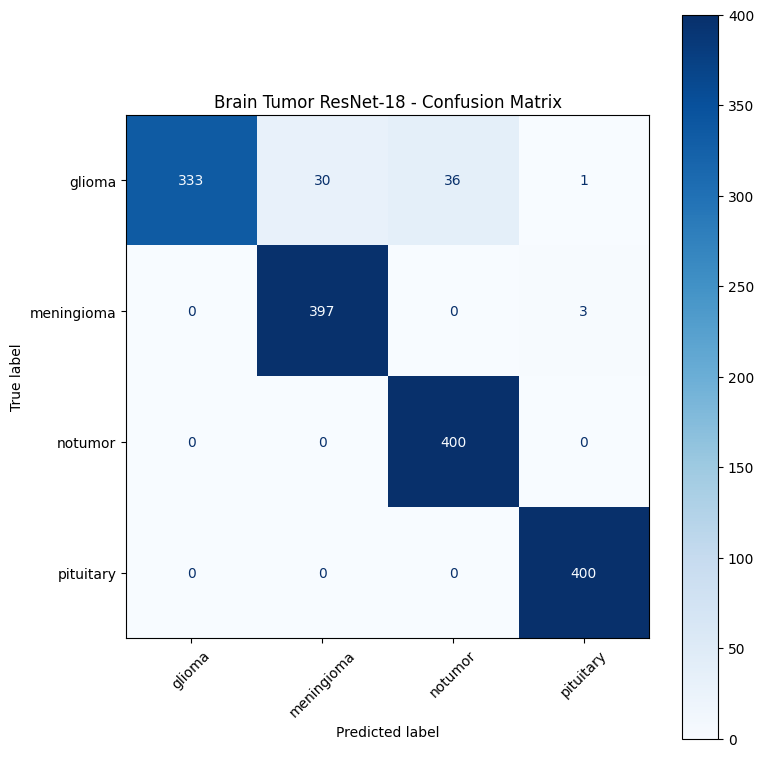

In [51]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    all_labels,
    all_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_dataset.classes
)

fig, ax = plt.subplots(figsize=(8, 8))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("Brain Tumor ResNet-18 - Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [52]:
import os

MODEL_DIR = os.path.join(PROJECT_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

ONNX_PATH = os.path.join(
    MODEL_DIR,
    "brain_tumor_resnet18.onnx"
)

print("ONNX will be saved to:")
print(ONNX_PATH)

ONNX will be saved to:
/content/drive/MyDrive/synpase/synpase/archive/models/brain_tumor_resnet18.onnx


In [53]:
model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [54]:
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Loaded best checkpoint.")
print("Best epoch:", checkpoint["epoch"])
print("Accuracy:", checkpoint["accuracy"] * 100)

Loaded best checkpoint.
Best epoch: 7
Accuracy: 95.625


In [58]:
!pip install -q onnx onnxscript

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 20.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 15.5 MB/s eta 0:00:00


In [59]:
from torchvision import models

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = models.resnet18(
    weights=None
)

model.fc = nn.Linear(
    model.fc.in_features,
    4
)

model = model.to(device)

print("Model ready on:", device)

Model ready on: cuda


In [60]:
BEST_MODEL_PATH = "/content/drive/MyDrive/synpase/synpase/archive/checkpoints/brain_tumor_resnet18_best.pth"

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Loaded checkpoint")
print("Best epoch:", checkpoint["epoch"])
print("Accuracy:", checkpoint["accuracy"] * 100)

Loaded checkpoint
Best epoch: 7
Accuracy: 95.625


In [61]:
import os

MODEL_DIR = "/content/drive/MyDrive/synpase/synpase/archive/models"

os.makedirs(MODEL_DIR, exist_ok=True)

ONNX_PATH = os.path.join(
    MODEL_DIR,
    "brain_tumor_resnet18.onnx"
)

In [62]:
dummy_input = torch.randn(
    1, 3, 224, 224,
    device=device
)

torch.onnx.export(
    model,
    dummy_input,
    ONNX_PATH,
    export_params=True,
    opset_version=18,
    input_names=["image"],
    output_names=["output"],
    dynamic_axes={
        "image": {0: "batch_size"},
        "output": {0: "batch_size"}
    }
)

print("ONNX export complete!")
print(ONNX_PATH)

/tmp/ipykernel_845/3877003597.py:6: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(


[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/usr/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ONNX export complete!
/content/drive/MyDrive/synpase/synpase/archive/models/brain_tumor_resnet18.onnx


In [63]:
print(f"ONNX size: {os.path.getsize(ONNX_PATH) / (1024 * 1024):.2f} MB")

onnx_model = onnx.load(ONNX_PATH)
onnx.checker.check_model(onnx_model)

print(" ONNX model is valid!")

ONNX size: 0.09 MB
 ONNX model is valid!


In [64]:
print("Best epoch:", checkpoint["epoch"])
print("Accuracy:", checkpoint["accuracy"] * 100)

total_params = sum(
    p.numel() for p in model.parameters()
)

print("Total parameters:", total_params)
print(f"Parameter size: {total_params * 4 / (1024 * 1024):.2f} MB")

Best epoch: 7
Accuracy: 95.625
Total parameters: 11178564
Parameter size: 42.64 MB


In [65]:
import os

if os.path.exists(ONNX_PATH):
    os.remove(ONNX_PATH)

print("Old ONNX removed.")

Old ONNX removed.


In [66]:
import torch

model.eval()

dummy_input = torch.randn(
    1, 3, 224, 224,
    device=device
)

torch.onnx.export(
    model,
    dummy_input,
    ONNX_PATH,

    export_params=True,

    opset_version=17,

    input_names=["image"],
    output_names=["output"],

    dynamic_axes={
        "image": {0: "batch_size"},
        "output": {0: "batch_size"}
    },

    do_constant_folding=True,

    # IMPORTANT:
    # Force weights into the ONNX file itself
    external_data=False,

    # Use the traditional exporter
    dynamo=False
)

print("ONNX export complete!")
print(ONNX_PATH)

/tmp/ipykernel_845/3677943102.py:10: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


ONNX export complete!
/content/drive/MyDrive/synpase/synpase/archive/models/brain_tumor_resnet18.onnx


In [67]:
size_mb = os.path.getsize(ONNX_PATH) / (1024 * 1024)

print(f"ONNX size: {size_mb:.2f} MB")

ONNX size: 42.63 MB


In [68]:
import onnxruntime as ort
import numpy as np

session = ort.InferenceSession(
    ONNX_PATH,
    providers=["CPUExecutionProvider"]
)

print("ONNX Runtime loaded successfully!")

ONNX Runtime loaded successfully!


In [69]:
import onnxruntime as ort
import numpy as np

session = ort.InferenceSession(
    ONNX_PATH,
    providers=["CPUExecutionProvider"]
)

print("ONNX Runtime loaded successfully!")

print("Input:", session.get_inputs()[0].name)
print("Output:", session.get_outputs()[0].name)

ONNX Runtime loaded successfully!
Input: image
Output: output


In [70]:
image, true_label = test_dataset[0]

print("True class:", test_dataset.classes[true_label])
print("Image shape:", image.shape)

True class: glioma
Image shape: torch.Size([3, 224, 224])


In [71]:
model.eval()

input_tensor = image.unsqueeze(0).to(device)

with torch.no_grad():
    pytorch_output = model(input_tensor)

pytorch_output = pytorch_output.cpu().numpy()

print("PyTorch output:")
print(pytorch_output)

PyTorch output:
[[ 0.39957792 -0.5861709  -0.37979165 -1.2990583 ]]


In [72]:
onnx_input = image.unsqueeze(0).numpy().astype(np.float32)

onnx_output = session.run(
    ["output"],
    {"image": onnx_input}
)[0]

print("ONNX output:")
print(onnx_output)

ONNX output:
[[ 0.39957097 -0.58617353 -0.37978524 -1.2990546 ]]


In [73]:
difference = np.abs(
    pytorch_output - onnx_output
)

print("Maximum difference:", difference.max())
print("Mean difference:", difference.mean())

pytorch_class = np.argmax(pytorch_output)
onnx_class = np.argmax(onnx_output)

print("\nPyTorch prediction:",
      test_dataset.classes[pytorch_class])

print("ONNX prediction:",
      test_dataset.classes[onnx_class])

print("\nTrue class:",
      test_dataset.classes[true_label])

Maximum difference: 6.943941e-06
Mean difference: 4.917383e-06

PyTorch prediction: glioma
ONNX prediction: glioma

True class: glioma
